### Model Test

LightGBM 0.37969

Rf 0.15820

xgboost 0.30579

HistGradientBoostingClassifier 0.28893

In [ ]:
# 安裝必要套件（如果尚未安裝）
!pip install lightgbm xgboost scikit-learn

# 匯入模組
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
import time

# 讀取資料
data = pd.read_csv('train.csv')
if 'Unnamed: 0' in data.columns:
    data = data.rename(columns={'Unnamed: 0': 'index'})
if 'index' in data.columns:
    data = data.drop(columns=['index'])

# 拆分特徵與標籤
X = data.drop(columns=['target'])
y = data['target']

# 拆分訓練與驗證資料
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 儲存模型與結果
models = {
    'LightGBM': LGBMClassifier(
        n_estimators=500, learning_rate=0.05, max_depth=10, class_weight='balanced',num_leaves=64,
        subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1
    ),
    'XGBoost': XGBClassifier(
        n_estimators=500, learning_rate=0.05, max_depth=10, scale_pos_weight=1,
        subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1,
        use_label_encoder=False, eval_metric='logloss'
    ),
    'RandomForest': RandomForestClassifier(
        n_estimators=300, max_depth=15, class_weight='balanced', random_state=42, n_jobs=-1
    )
}

results = {}


In [ ]:
# 訓練與評估
for name, model in models.items():
    print(f"\n==== 訓練 {name} ====")
    start = time.time()

    if name == 'LightGBM':
      import lightgbm
      model.fit(
          X_train, y_train,
          eval_set=[(X_val, y_val)],
          callbacks=[
              lightgbm.early_stopping(stopping_rounds=50),
              lightgbm.log_evaluation(period=100)
          ]
      )
    if name == 'XGBoost':
      model.fit(X_train, y_train)
    else:
        model.fit(X_train, y_train)


    y_pred = model.predict(X_val)
    f1 = f1_score(y_val, y_pred)
    results[name] = f1
    print(f"\n{name} F1 分數: {f1:.4f}")
    print(classification_report(y_val, y_pred))

# 最終 F1 分數總覽
print("\n==== 模型 F1 分數比較 ====")
for name, f1 in results.items():
    print(f"{name}: F1 = {f1:.4f}")


==== 訓練 LightGBM ====
[LightGBM] [Info] Number of positive: 50438, number of negative: 74422
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.119276 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 8540
[LightGBM] [Info] Number of data points in the train set: 124860, number of used features: 95
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
Training until validation scores don't improve for 50 rounds
[100]	valid_0's binary_logloss: 0.30475
[200]	valid_0's binary_logloss: 0.300754
[300]	valid_0's binary_logloss: 0.300188
[400]	valid_0's binary_logloss: 0.299607
[500]	valid_0's binary_logloss: 0.299329
Did not meet early stopping. Best iteration is:
[500]	valid_0's binary_logloss: 0.299329
[LightGBM] [Info] Number of positive: 50438, number of negative: 74422
[LightGBM] [Info] Auto-choosing col-wise multi-threading,

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [09:24:38] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



XGBoost F1 分數: 0.8246
              precision    recall  f1-score   support

           0       0.84      0.97      0.90     18606
           1       0.95      0.73      0.82     12610

    accuracy                           0.87     31216
   macro avg       0.89      0.85      0.86     31216
weighted avg       0.88      0.87      0.87     31216


==== 訓練 RandomForest ====

RandomForest F1 分數: 0.8157
              precision    recall  f1-score   support

           0       0.83      0.99      0.90     18606
           1       0.98      0.70      0.82     12610

    accuracy                           0.87     31216
   macro avg       0.91      0.84      0.86     31216
weighted avg       0.89      0.87      0.87     31216


==== 模型 F1 分數比較 ====
LightGBM: F1 = 0.8310
XGBoost: F1 = 0.8246
RandomForest: F1 = 0.8157


In [ ]:
import pandas as pd

# 讀取測試資料
new_data = pd.read_csv('test.csv')
print("原始欄位：", new_data.columns)

# 保留 index 欄（如果要輸出原本的 index，可修改）
if 'index' in new_data.columns:
    original_index = new_data['index']
    new_data = new_data.drop(columns=['index'])
else:
    original_index = pd.Series(range(len(new_data)))

# 對三個模型預測
y_pred_lgb = models['LightGBM'].predict(new_data)
y_pred_xgb = models['XGBoost'].predict(new_data)
y_pred_rf  = models['RandomForest'].predict(new_data)

# 儲存每個模型預測結果
output_lgb = pd.DataFrame({'index': original_index, 'target': y_pred_lgb})
output_xgb = pd.DataFrame({'index': original_index, 'target': y_pred_xgb})
output_rf  = pd.DataFrame({'index': original_index, 'target': y_pred_rf})

output_lgb.to_csv('predictions_lightgbm.csv', index=False)
output_xgb.to_csv('predictions_xgboost.csv', index=False)
output_rf.to_csv('predictions_rf.csv', index=False)

# 顯示結果（可選）
print("\n[LightGBM] 預測前 5 筆：")
print(output_lgb.head())

print("\n[XGBoost] 預測前 5 筆：")
print(output_xgb.head())

print("\n[RandomForest] 預測前 5 筆：")
print(output_rf.head())


原始欄位： Index(['index', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11',
       '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23',
       '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35',
       '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47',
       '48', '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59',
       '60', '61', '62', '63', '64', '65', '66', '67', '68', '69', '70', '71',
       '72', '73', '74', '75', '76', '77', '78', '79', '80', '81', '82', '83',
       '84', '85', '86', '87', '88', '89', '90', '91', '92', '93', '94', '95'],
      dtype='object')

[LightGBM] 預測前 5 筆：
   index  target
0      0       0
1      1       0
2      2       0
3      3       1
4      4       0

[XGBoost] 預測前 5 筆：
   index  target
0      0       0
1      1       0
2      2       0
3      3       1
4      4       0

[RandomForest] 預測前 5 筆：
   index  target
0      0       0
1      1       0
2      2       0
3 

In [ ]:
# 安裝必要套件（如果還沒安裝）
!pip install scikit-learn

# 匯入模組
import numpy as np
import pandas as pd
from sklearn.experimental import enable_hist_gradient_boosting
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.metrics import classification_report
from scipy.stats import uniform, randint

# 讀取訓練資料
data = pd.read_csv('train.csv')
data = data.rename(columns={'Unnamed: 0': 'index'})
print(data.columns)

# 移除 'index' 欄（若存在），避免作為特徵；保留 target
X = data.drop(columns=['index', 'target']) if 'index' in data.columns else data.drop(columns=['target'])
y = data['target']
print(X.columns)


# 拆分訓練與驗證資料
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 定義參數搜尋空間
param_dist = {
    'max_iter': randint(500, 2000),
    'learning_rate': uniform(0.005, 0.045),
    'max_depth': randint(4, 15),
    'min_samples_leaf': randint(10, 100),
    'l2_regularization': uniform(0.1, 4.9),
}

# 設定基本模型
base_model = HistGradientBoostingClassifier(
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20,
    random_state=42
)

# 隨機搜尋最佳參數
search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=param_dist,
    n_iter=50,
    scoring='f1',
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1,
    refit=True
)

# 模型訓練
search.fit(X_train, y_train)

# 訓練評估
y_pred = search.predict(X_test)
print("Best Parameters:", search.best_params_)
print("\nClassification Report:\n", classification_report(y_test, y_pred))

In [ ]:
new_data = pd.read_csv('rename.csv')
print(new_data.columns)

# 移除index
new_data = new_data.drop(columns=['index'])

y_pred_new = search.predict(new_data)

output_df = pd.DataFrame({
    'index': range(len(new_data)),  # 從 0 開始的連續編號
    'target': y_pred_new
})

# 儲存結果到 CSV
output_df.to_csv('predictions.csv', index=False)

# 顯示預測結果
print(output_df)

HistGradientBoostingClassifier 0.28893

LightGBM 0.37969

Rf 0.15820

xgboost 0.30579

### LightGBM

In [ ]:
# 安裝必要套件
!pip install lightgbm

# 匯入模組
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import classification_report
from lightgbm import LGBMClassifier
from scipy.stats import uniform, randint

# 讀取資料
data = pd.read_csv('train.csv')
data = data.rename(columns={'Unnamed: 0': 'index'})
X = data.drop(columns=['index', 'target']) if 'index' in data.columns else data.drop(columns=['target'])
y = data['target']

# 拆分資料
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 建立 LightGBM 模型
lgb_model = LGBMClassifier(
    objective='binary',
    class_weight='balanced',  # 自動處理不平衡類別
    boosting_type='gbdt',
    random_state=42
)

# 定義參數搜尋範圍
# param_dist = {
#     'n_estimators': randint(300, 1200),
#     'learning_rate': uniform(0.01, 0.1),
#     'max_depth': randint(3, 15),
#     'num_leaves': randint(20, 150),
#     'min_child_samples': randint(10, 100),
#     'subsample': uniform(0.6, 0.4),
#     'colsample_bytree': uniform(0.6, 0.4),
#     'reg_alpha': uniform(0.0, 2.0),
#     'reg_lambda': uniform(0.0, 2.0)
# }
param_dist = {
    'n_estimators': randint(500, 2000),
    'learning_rate': uniform(0.01, 0.05),
    'max_depth': randint(6, 20),
    'num_leaves': randint(31, 200),
    'min_child_samples': randint(20, 300),
    'subsample': uniform(0.6, 0.3),
    'colsample_bytree': uniform(0.4, 0.6),
    'reg_alpha': uniform(0.0, 3.0),
    'reg_lambda': uniform(0.0, 3.0)
}


# 使用隨機搜尋找最佳參數
search = RandomizedSearchCV(
    estimator=lgb_model,
    param_distributions=param_dist,
    n_iter=50,
    scoring='f1',
    cv=3,
    random_state=42,
    verbose=2,
    n_jobs=-1
)

# 訓練模型
search.fit(X_train, y_train)

# 預測與報告
y_pred = search.predict(X_test)
print("Best Parameters:", search.best_params_)
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Fitting 3 folds for each of 50 candidates, totalling 150 fits
[LightGBM] [Info] Number of positive: 50656, number of negative: 74204
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.063652 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 8540
[LightGBM] [Info] Number of data points in the train set: 124860, number of used features: 95
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain

In [ ]:
# 定義參數搜尋範圍
param_dist = {
    'n_estimators': randint(300, 1200),
    'learning_rate': uniform(0.01, 0.1),
    'max_depth': randint(3, 15),
    'num_leaves': randint(20, 150),
    'min_child_samples': randint(10, 100),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'reg_alpha': uniform(0.0, 2.0),
    'reg_lambda': uniform(0.0, 2.0)
}

In [ ]:
new_data = pd.read_csv('test.csv')
print(new_data.columns)

# 移除index
new_data = new_data.drop(columns=['index'])

y_pred_new = search.predict(new_data)

output_df = pd.DataFrame({
    'index': range(len(new_data)),  # 從 0 開始的連續編號
    'target': y_pred_new
})

# 儲存結果到 CSV
output_df.to_csv('predictions.csv', index=False)

# 顯示預測結果
print(output_df)

Index(['index', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11',
       '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23',
       '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35',
       '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47',
       '48', '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59',
       '60', '61', '62', '63', '64', '65', '66', '67', '68', '69', '70', '71',
       '72', '73', '74', '75', '76', '77', '78', '79', '80', '81', '82', '83',
       '84', '85', '86', '87', '88', '89', '90', '91', '92', '93', '94', '95'],
      dtype='object')
         index  target
0            0       0
1            1       0
2            2       0
3            3       1
4            4       0
...        ...     ...
194325  194325       0
194326  194326       0
194327  194327       0
194328  194328       0
194329  194329       0

[194330 rows x 2 columns]


## Improvement

In [ ]:
# 讀取資料
data = pd.read_csv('train.csv')
data = data.rename(columns={'Unnamed: 0': 'index'})
X = data.drop(columns=['index', 'target']) if 'index' in data.columns else data.drop(columns=['target'])
y = data['target']

# 拆分資料
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
import joblib
import matplotlib.pyplot as plt

def predict_and_save(model, model_name, test_path='test.csv', output_path='predictions.csv'):
    # 載入新資料
    new_data = pd.read_csv(test_path)
    print(f"[{model_name}] 原始欄位：", new_data.columns.tolist())

    if 'index' in new_data.columns:
        new_data = new_data.drop(columns=['index'])

    # 預測
    y_pred_new = model.predict(new_data)

    # 儲存預測結果
    output_df = pd.DataFrame({
        'index': range(len(new_data)),
        'target': y_pred_new
    })

    output_file = f'{model_name}_{output_path}'
    output_df.to_csv(output_file, index=False)
    print(f"[{model_name}] 預測結果儲存至：{output_file}")
    print(output_df.head())

    # 儲存模型
    model_file = f'{model_name}_model.pkl'
    joblib.dump(model, model_file)
    print(f"[{model_name}] 模型儲存至：{model_file}")

    # 繪製特徵重要性圖
    plt.figure(figsize=(10, 6))
    if hasattr(model, 'feature_importances_'):
        importances = model.feature_importances_
        feature_names = new_data.columns
        sorted_idx = np.argsort(importances)[::-1]
        plt.bar(range(len(importances)), importances[sorted_idx], align='center')
        plt.xticks(range(len(importances)), feature_names[sorted_idx], rotation=90)
        plt.title(f"{model_name} Feature Importance")
        plt.tight_layout()
        plt.savefig(f"{model_name}_feature_importance.png")
        print(f"[{model_name}] 特徵重要性圖已儲存：{model_name}_feature_importance.png")
        plt.show()
    else:
        print(f"[{model_name}] 模型不支援 feature_importances_")

### LightBGM

In [ ]:
!pip install -U lightgbm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 24.7 MB/s eta 0:00:00
  Attempting uninstall: lightgbm
    Found existing installation: lightgbm 4.5.0
    Uninstalling lightgbm-4.5.0:
      Successfully uninstalled lightgbm-4.5.0


In [ ]:
from lightgbm import LGBMClassifier
from sklearn.metrics import classification_report, f1_score
import time

def train_lightgbm(X_train, X_val, y_train, y_val):
    print("Training LightGBM...")
    start_time = time.time()

    model = LGBMClassifier(
        n_estimators=1000,
        learning_rate=0.03,
        max_depth=10,
        num_leaves=64,
        subsample=0.8,
        colsample_bytree=0.8,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
        # early_stopping(stopping_rounds=50)
    )

    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        eval_metric='f1',
        # early_stopping_rounds=50,
        # verbose=100
    )


    preds = model.predict(X_val)
    f1 = f1_score(y_val, preds, average='macro')
    print(f"\nF1 Score (macro): {f1:.4f}")
    print(classification_report(y_val, preds))
    print(f"Training completed in {time.time() - start_time:.2f} seconds\n")

    return model


Training LightGBM...
[LightGBM] [Info] Number of positive: 50656, number of negative: 74204
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.134792 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 8540
[LightGBM] [Info] Number of data points in the train set: 124860, number of used features: 95
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000

F1 Score (macro): 0.9173
              precision    recall  f1-score   support

           0       0.90      0.98      0.94     18606
           1       0.96      0.84      0.90     12610

    accuracy                           0.92     31216
   macro avg       0.93      0.91      0.92     31216
weighted avg       0.93      0.92      0.92     31216

Training completed in 42.15 seconds

[LightGBM] 原始欄位： ['index', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12',

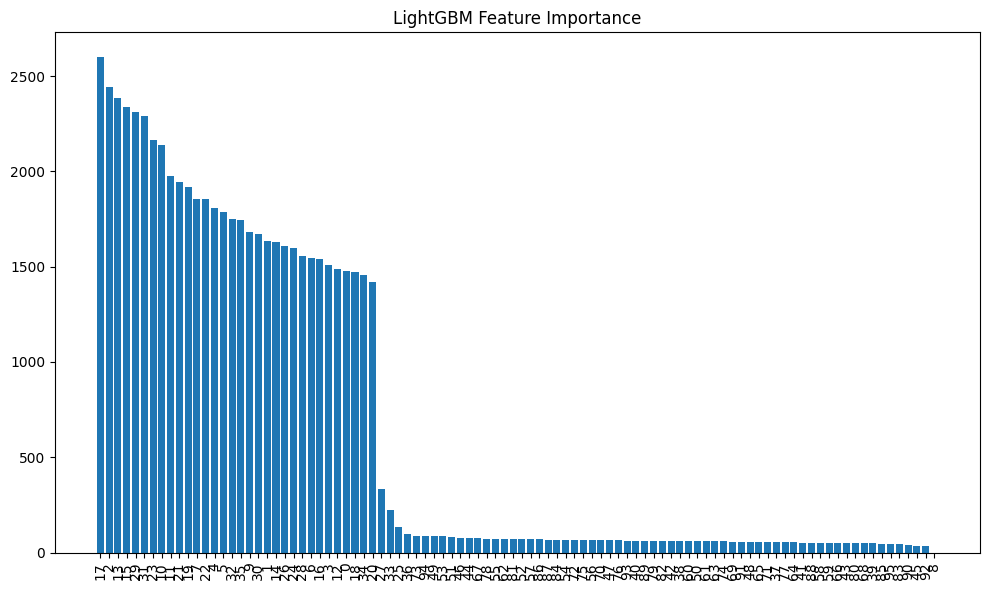

In [ ]:
lightgbm_model = train_lightgbm(X_train, X_val, y_train, y_val)
predict_and_save(lightgbm_model, 'LightGBM', test_path='/content/test.csv')

### XGBoot

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, f1_score
import time

def train_xgboost(X_train, X_val, y_train, y_val):
    print("Training XGBoost...")
    start_time = time.time()

    # 計算 scale_pos_weight（以 binary 為例）
    pos = sum(y_train == 1)
    neg = sum(y_train == 0)
    scale_pos_weight = neg / pos if pos > 0 else 1

    model = XGBClassifier(
        n_estimators=1000,
        learning_rate=0.03,
        max_depth=10,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        n_jobs=-1,
        use_label_encoder=False,
        eval_metric='logloss'
    )

    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        # early_stopping_rounds=50,
        verbose=100,
    )

    preds = model.predict(X_val)
    f1 = f1_score(y_val, preds, average='macro')
    print(f"\nF1 Score (macro): {f1:.4f}")
    print(classification_report(y_val, preds))
    print(f"Training completed in {time.time() - start_time:.2f} seconds\n")

    return model


Training XGBoost...


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [11:15:38] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


[0]	validation_0-logloss:0.67621
[100]	validation_0-logloss:0.27515
[200]	validation_0-logloss:0.23769
[300]	validation_0-logloss:0.21756
[400]	validation_0-logloss:0.19539
[500]	validation_0-logloss:0.17641
[600]	validation_0-logloss:0.15995
[700]	validation_0-logloss:0.14548
[800]	validation_0-logloss:0.13380
[900]	validation_0-logloss:0.12362
[999]	validation_0-logloss:0.11563

F1 Score (macro): 0.9724
              precision    recall  f1-score   support

           0       0.96      0.99      0.98     18606
           1       0.99      0.94      0.97     12610

    accuracy                           0.97     31216
   macro avg       0.98      0.97      0.97     31216
weighted avg       0.97      0.97      0.97     31216

Training completed in 182.63 seconds

[XGBoost] 原始欄位： ['index', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', 

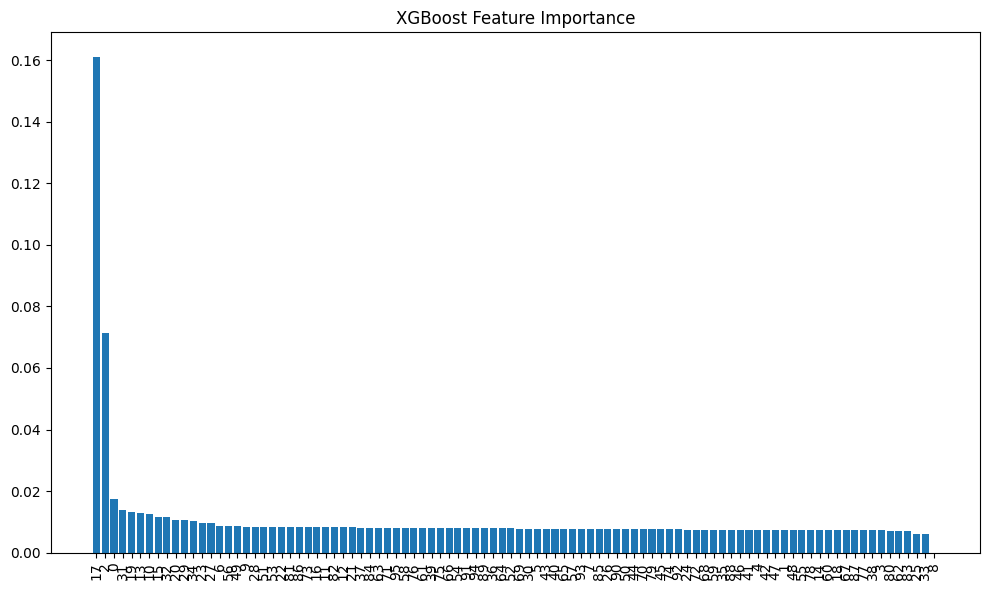

In [ ]:
xgboost_model = train_xgboost(X_train, X_val, y_train, y_val)
predict_and_save(xgboost_model, 'XGBoost', test_path='/content/test.csv')